In [ ]:
# Core RAG Frameworks
!pip install langgraph
!pip install langchain-openai
!pip install langchain-community
!pip install langchain-text-splitters
!pip install langchain
!pip install faiss-cpu
!pip install tiktoken
!pip install openai
!pip install grandalf
!pip install chromadb

In [ ]:
# Import all depedencies for tools

import json
import os
from typing import List, Dict, Any
from langchain_core.tools import Tool
from langchain_openai import OpenAIEmbeddings
from langchain_community.vectorstores import Chroma
from langchain_core.documents import Document

# Import the Python SDK for Colab secrets
from google.colab import userdata

/tmp/ipykernel_6879/1379025684.py:8: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.vectorstores import Chroma


In [ ]:
import os

# Fetch the API key from Colab secrets
OPENAI_API_KEY = userdata.get('OPENAI_APIKEY')

# Set up Environmental Variables
OPENAI_EMBEDDING_MODEL = "text-embedding-3-small"

In [ ]:
class SupportTicketTools:
    """Collection of tools for the support assistant agent."""
    def __init__(self, tickets_path: str = './sample_data/synthetic_tickets.json'):
        """
        Initialize ticket data + retrieval infrastructure once at startup.
        This keeps tool calls fast because embeddings/vector index are prepared
        ahead of time rather than rebuilt per request.
        """
        # Load tickets
        with open(tickets_path, 'r', encoding='utf-8') as f:
            self.tickets = json.load(f)
        # Create vector store for RAG
        self.embeddings = OpenAIEmbeddings(
            model=OPENAI_EMBEDDING_MODEL,
            openai_api_key=OPENAI_API_KEY
        )
        self.setup_vectorstore()

    def setup_vectorstore(self):
        """
        Build a semantic-search index from ticket text.
        Each ticket becomes one Document with metadata so agent responses can
        include both narrative context and structured filters/citations.
        """
        documents = []
        for ticket in self.tickets:
            content = f"""Ticket ID: {ticket['ticket_id']}
Title: {ticket['title']}
Description: {ticket['description']}
Resolution: {ticket['resolution']}
Category: {ticket['category']}
Priority: {ticket['priority']}"""
            doc = Document(
                page_content=content,
                metadata={
                    'ticket_id': ticket['ticket_id'],
                    'category': ticket['category'],
                    'priority': ticket['priority'],
                    'title': ticket['title']
                }
            )
            documents.append(doc)
        # Persist locally so repeated runs reuse indexed data on disk.
        self.vectorstore = Chroma.from_documents(
            documents=documents,
            embedding=self.embeddings,
            persist_directory="./agent_vectorstore"
        )

    def search_similar_tickets(self, query: str) -> str:
        """
        Search for similar support tickets using semantic similarity.
        Args:
            query: User's problem description or question
        Returns:
            Formatted string with relevant tickets
        """
        # Top-k semantic retrieval by embedding similarity.
        results = self.vectorstore.similarity_search(query, k=3)
        if not results:
            return "No similar tickets found."
        output = "Found similar tickets:\n\n"
        for i, doc in enumerate(results, 1):
            output += f"--- Ticket {i} ---\n"
            output += doc.page_content + "\n\n"
        return output

    def get_ticket_by_id(self, ticket_id: str) -> str:
        """
        Retrieve a specific ticket by its ID.
        Args:
            ticket_id: The ticket ID (e.g., TICK-001)
        Returns:
            Formatted ticket details or error message
        """
        # Normalize input to avoid case/whitespace mismatches.
        ticket_id = ticket_id.upper().strip()
        for ticket in self.tickets:
            if ticket['ticket_id'] == ticket_id:
                return f"""Ticket ID: {ticket['ticket_id']}
Title: {ticket['title']}
Description: {ticket['description']}
Resolution: {ticket['resolution']}
Category: {ticket['category']}
Priority: {ticket['priority']}
Created: {ticket['created_date']}
Resolved: {ticket['resolved_date']}"""
        return f"Ticket {ticket_id} not found in the database."

    def search_by_category(self, category: str) -> str:
        """
        Find all tickets in a specific category.
        Args:
            category: Category name (e.g., Authentication, Database, Payment)
        Returns:
            List of tickets in the category
        """
        # Normalize category string for case-insensitive exact matching.
        category = category.strip()
        matching = [t for t in self.tickets if t['category'].lower() == category.lower()]
        if not matching:
            available = list(set(t['category'] for t in self.tickets))
            return f"No tickets found in category '{category}'. Available categories: {', '.join(available)}"
        output = f"Found {len(matching)} tickets in category '{category}':\n\n"
        for ticket in matching:
            output += f"• [{ticket['ticket_id']}] {ticket['title']} (Priority: {ticket['priority']})\n"
        return output

    def get_ticket_statistics(self, _: str = "") -> str:
        """
        Get statistics and insights about the ticket database.
        Returns:
            Statistics about tickets
        """
        total = len(self.tickets)
        # Aggregate counts for dashboard/overview style questions.
        # Using dict accumulation keeps this dependency-free and explicit.
        categories = {}
        priorities = {}
        for ticket in self.tickets:
            categories[ticket['category']] = categories.get(ticket['category'], 0) + 1
            priorities[ticket['priority']] = priorities.get(priority['priority'], 0) + 1
        output = f"Ticket Database Statistics:\n"
        output += f"Total Tickets: {total}\n\n"
        output += "By Category:\n"
        for cat, count in sorted(categories.items(), key=lambda x: x[1], reverse=True):
            output += f"  • {cat}: {count}\n"
        output += "\nBy Priority:\n"
        for pri, count in sorted(priorities.items(), key=lambda x: x[1], reverse=True):
            output += f"  • {pri}: {count}\n"
        return output

    def get_tools(self) -> List[Tool]:
        """
        Get all tools as LangChain Tool objects.
        Returns:
            List of Tool objects for the agent
        """
        # Tool descriptions are part of the model prompt context.
        # High-quality descriptions materially improve tool-selection accuracy.
        return [
            Tool(
                name="SearchSimilarTickets",
                func=self.search_similar_tickets,
                description="""Use this tool to search for similar support tickets based on a problem description or question.
Input should be a clear description of the issue or question.
This is the PRIMARY tool for answering "how to fix" or "similar issue" questions."""
            ),
            Tool(
                name="GetTicketByID",
                func=self.get_ticket_by_id,
                description="""Use this tool to retrieve details of a specific ticket by its ID.
Input should be a ticket ID like 'TICK-001'.
Use this when the user mentions a specific ticket number."""
            ),
            Tool(
                name="SearchByCategory",
                func=self.search_by_category,
                description="""Use this tool to find all tickets in a specific category.
Input should be a category name like 'Authentication', 'Database', 'Payment', 'Mobile', etc.
Use this when the user wants to see all issues of a certain type."""
            ),
            Tool(
                name="GetTicketStatistics",
                func=self.get_ticket_statistics,
                description="""Use this tool to get statistics about the ticket database including total count,
category distribution, and priority breakdown.
No input needed - just call this tool.
Use this when the user asks for statistics, summaries, or overview of tickets."""
            )
        ]

In [ ]:

# Import all depedencies for Langraph

import os
from typing import Annotated, TypedDict
from dotenv import load_dotenv

from langchain_openai import ChatOpenAI
from langchain_core.messages import HumanMessage, BaseMessage, SystemMessage
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode, tools_condition
from langgraph.checkpoint.memory import MemorySaver
from IPython.display import display,Image






In [ ]:

# Fetch the API key from Colab secrets
openai_api_key = userdata.get('OPENAI_APIKEY')

# Set up Environmental Variables
os.environ["OPENAI_API_KEY"] = openai_api_key

In [ ]:

# ============================================================================
# PART 1: Setup LangGraph Agent & Tools
# ============================================================================
print("\n" + "="*80)
print("PART 1: Setting Up the LangGraph Agent")
print("="*80)




PART 1: Setting Up the LangGraph Agent


In [ ]:
print("\nInitializing LLM...")
llm = ChatOpenAI(
    model=os.getenv('OPENAI_CHAT_MODEL', 'gpt-4o-mini'),
    temperature=0,
    api_key=os.getenv('OPENAI_API_KEY')
)
print("✓ LLM initialized")


Initializing LLM...
✓ LLM initialized


In [ ]:
print("\nCreating agent tools...")
tool_manager = SupportTicketTools()
tools = tool_manager.get_tools()


Creating agent tools...


In [ ]:
# Bind tools natively using LangChain's bind_tools (no manual JSON schema required)
llm_with_tools = llm.bind_tools(tools)

print(f"✓ Created {len(tools)} tools:")
for tool in tools:
    print(f"  • {tool.name}: {tool.description.split('.')[0]}")

✓ Created 4 tools:
  • SearchSimilarTickets: Use this tool to search for similar support tickets based on a problem description or question
  • GetTicketByID: Use this tool to retrieve details of a specific ticket by its ID
  • SearchByCategory: Use this tool to find all tickets in a specific category
  • GetTicketStatistics: Use this tool to get statistics about the ticket database including total count,
category distribution, and priority breakdown


In [ ]:
# Define State Schema
class AgentState(TypedDict):
    # `add_messages` ensures new messages are appended rather than overwriting existing state
    messages: Annotated[list[BaseMessage], add_messages]

# System Instructions
SYSTEM_PROMPT = SystemMessage(content="""You are an expert support desk assistant that helps troubleshoot technical issues.

You have access to a database of previous support tickets with their resolutions.
Use your tools to find relevant information and provide helpful, accurate answers.

Guidelines:
- ALWAYS search for similar tickets when asked about troubleshooting or "how to fix" questions
- Be specific and reference ticket IDs when providing solutions
- If multiple similar issues exist, mention the most relevant ones
- Admit when you don't have enough information
- Be concise but thorough in your responses
- When appropriate, use multiple tools to gather complete information
- Before each tool call, provide a short public rationale in content using this exact prefix:
    "Decision: <one sentence explaining why this tool is needed>"

Remember: Your primary value is retrieving and applying solutions from past tickets!""")

In [ ]:
# Define Agent Node
def call_model(state: AgentState):
    """LLM Node: Invocated with current state history + System Prompt."""
    messages = [SYSTEM_PROMPT] + state["messages"]
    response = llm_with_tools.invoke(messages)
    return {"messages": [response]}

In [ ]:
# Build Graph
builder = StateGraph(AgentState)

In [ ]:
# 1. Add Nodes
builder.add_node("agent", call_model)
builder.add_node("tools", ToolNode(tools)) # Handles execution of tool calls automatically

In [ ]:
# 2. Add Edges & Conditional Routing
builder.add_edge(START, "agent")
# Evaluates whether the LLM requested a tool call or is ready to finish
builder.add_conditional_edges("agent", tools_condition)
# Return back to agent after executing a tool
builder.add_edge("tools", "agent")
builder.add_edge("agent", END)

In [ ]:
# Compile basic graph (un-checkpointed for single-turn runs)
app = builder.compile()

In [ ]:
# Compile graph with MemorySaver (for multi-turn conversations)
memory = MemorySaver()
conversational_app = builder.compile(checkpointer=memory)

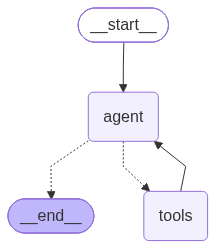

In [ ]:
# Show Chatbot Graph
display(Image(app.get_graph().draw_mermaid_png()))

In [ ]:
def run_agent(query: str) -> str:
    """Stream execution of single-turn queries and format terminal logs."""
    inputs = {"messages": [HumanMessage(content=query)]}
    final_output = ""

    # Stream node execution step-by-step
    for event in app.stream(inputs, stream_mode="updates"):
        for node_name, state_update in event.items():
            last_msg = state_update["messages"][-1]

            # Print decision traces if the agent emitted a rationale
            if node_name == "agent" and last_msg.tool_calls:
                decision_trace = (last_msg.content or "").strip()
                if decision_trace:
                    print(f"\n🧭 {decision_trace}")
                for tc in last_msg.tool_calls:
                    print(f"\n🔧 Calling tool: {tc['name']}")
                    print(f"   Input: {tc['args']}")

            # Print tool outputs
            elif node_name == "tools":
                print(f"   Output: {last_msg.content[:200]}...")

            # Capture final response
            if node_name == "agent" and not last_msg.tool_calls:
                final_output = last_msg.content

    return final_output

    print("\n✓ LangGraph Agent ready!")

In [ ]:
# ============================================================================
# PART 2: Simple Query - RAG Tool Selection
# ============================================================================
print("\n" + "="*80)
print("PART 2: Simple Query - Agent Selects RAG Tool")
print("="*80)

query1 = "How do I fix authentication problems after password reset?"
print(f"\nQuery: '{query1}'")
print("\nAgent will automatically:")
print("1. Recognize this is a troubleshooting question")
print("2. Choose the SearchSimilarTickets tool")
print("3. Retrieve relevant tickets")
print("4. Synthesize an answer\n")
print("-" * 80)

response1 = run_agent(query1)
print("\n" + "-" * 80)
print("FINAL ANSWER:")
print(response1)


PART 2: Simple Query - Agent Selects RAG Tool

Query: 'How do I fix authentication problems after password reset?'

Agent will automatically:
1. Recognize this is a troubleshooting question
2. Choose the SearchSimilarTickets tool
3. Retrieve relevant tickets
4. Synthesize an answer

--------------------------------------------------------------------------------

🔧 Calling tool: SearchSimilarTickets
   Input: {'__arg1': 'authentication problems after password reset'}
   Output: Found similar tickets:

--- Ticket 1 ---
Ticket ID: TICK-001
Title: Users unable to log in after password reset
Description: Multiple users reporting authentication failures after performing password ...

--------------------------------------------------------------------------------
FINAL ANSWER:
To resolve authentication problems after a password reset, you can refer to a similar issue documented in ticket **TICK-001**. Here’s a summary of the resolution:

- **Issue**: Users were unable to log in after perfo

In [ ]:
# ============================================================================
# PART 3: Specific Lookup - Different Tool
# ============================================================================
print("\n" + "="*80)
print("PART 3: Specific Ticket Lookup")
print("="*80)

query2 = "Show me details of ticket TICK-005"
print(f"\nQuery: '{query2}'")
print("\nAgent will:")
print("1. Recognize this asks for a specific ticket")
print("2. Choose the GetTicketByID tool")
print("3. Return the exact ticket\n")
print("-" * 80)

response2 = run_agent(query2)
print("\n" + "-" * 80)
print("FINAL ANSWER:")
print(response2)


PART 3: Specific Ticket Lookup

Query: 'Show me details of ticket TICK-005'

Agent will:
1. Recognize this asks for a specific ticket
2. Choose the GetTicketByID tool
3. Return the exact ticket

--------------------------------------------------------------------------------

🔧 Calling tool: GetTicketByID
   Input: {'__arg1': 'TICK-005'}
   Output: Ticket ID: TICK-005
Title: Memory leak in background worker process
Description: Background job processor showing steady memory increase over time. Process killed by OS after reaching 8GB memory usage...

--------------------------------------------------------------------------------
FINAL ANSWER:
Here are the details for ticket **TICK-005**:

- **Title**: Memory leak in background worker process
- **Description**: The background job processor was showing a steady increase in memory usage over time, leading to the process being killed by the OS after reaching 8GB. A daily restart was required to maintain functionality.
- **Resolution**: Me

In [ ]:
# ============================================================================
# PART 4: Category Filtering
# ============================================================================
print("\n" + "="*80)
print("PART 4: Category-Based Search")
print("="*80)

query3 = "What payment-related issues have we seen?"
print(f"\nQuery: '{query3}'")
print("\nAgent will:")
print("1. Identify this asks about a category of issues")
print("2. Choose the SearchByCategory tool")
print("3. Show all payment tickets\n")
print("-" * 80)

response3 = run_agent(query3)
print("\n" + "-" * 80)
print("FINAL ANSWER:")
print(response3)


PART 4: Category-Based Search

Query: 'What payment-related issues have we seen?'

Agent will:
1. Identify this asks about a category of issues
2. Choose the SearchByCategory tool
3. Show all payment tickets

--------------------------------------------------------------------------------

🔧 Calling tool: SearchByCategory
   Input: {'__arg1': 'Payment'}
   Output: Found 1 tickets in category 'Payment':

• [TICK-003] Payment processing fails for international cards (Priority: High)
...

--------------------------------------------------------------------------------
FINAL ANSWER:
We have one payment-related issue recorded:

- **Ticket ID:** TICK-003
  - **Issue:** Payment processing fails for international cards
  - **Priority:** High

If you need more details about this ticket or its resolution, please let me know!


In [ ]:
# ============================================================================
# PART 6: Multi-Step Reasoning
# ============================================================================
print("\n" + "="*80)
print("PART 6: Multi-Step Reasoning")
print("="*80)

query5 = "Find database-related critical issues and tell me how they were resolved"
print(f"\nQuery: '{query5}'")
print("\nAgent will need to:")
print("1. First get category statistics or search by category")
print("2. Then look up specific ticket details")
print("3. Synthesize the resolution information\n")
print("-" * 80)

response5 = run_agent(query5)
print("\n" + "-" * 80)
print("FINAL ANSWER:")
print(response5)


PART 6: Multi-Step Reasoning

Query: 'Find database-related critical issues and tell me how they were resolved'

Agent will need to:
1. First get category statistics or search by category
2. Then look up specific ticket details
3. Synthesize the resolution information

--------------------------------------------------------------------------------

🔧 Calling tool: SearchByCategory
   Input: {'__arg1': 'Database'}
   Output: Found 2 tickets in category 'Database':

• [TICK-002] Database connection timeout in production (Priority: Critical)
• [TICK-021] Database connection excedding in production (Priority: Critical)
...

🔧 Calling tool: GetTicketByID
   Input: {'__arg1': 'TICK-002'}

🔧 Calling tool: GetTicketByID
   Input: {'__arg1': 'TICK-021'}
   Output: Ticket ID: TICK-021
Title: Database connection excedding in production
Description: Application experiencing intermittent 500 errors. Logs show 'connection pool exhausted' and 'timeout waiting for con...

---------------------------

In [ ]:
# ============================================================================
# PART 7: Conversational Agent with Memory (LangGraph Threading)
# ============================================================================
print("\n" + "="*80)
print("PART 7: Conversational Agent with Memory (LangGraph Checkpointer)")
print("="*80)

print("\nSimulating a multi-turn conversation using thread_id...")

def run_conversational_turn(thread_id: str, query: str) -> str:
    """Execute a turn against a checkpointed graph using `thread_id` state persistence."""
    config = {"configurable": {"thread_id": thread_id}}
    inputs = {"messages": [HumanMessage(content=query)]}
    final_output = ""

    for event in conversational_app.stream(inputs, config, stream_mode="updates"):
        for node_name, state_update in event.items():
            last_msg = state_update["messages"][-1]

            if node_name == "agent" and last_msg.tool_calls:
                decision_trace = (last_msg.content or "").strip()
                if decision_trace:
                    print(f"\n🧭 {decision_trace}")
                for tc in last_msg.tool_calls:
                    print(f"\n🔧 Calling tool: {tc['name']}")
                    print(f"   Input: {tc['args']}")

            elif node_name == "tools":
                print(f"   Output: {last_msg.content[:200]}...")

            if node_name == "agent" and not last_msg.tool_calls:
                final_output = last_msg.content

    return final_output

# Define a persistent session thread
THREAD_ID = "support_session_001"

print("\n--- Conversation Turn 1 ---")
conv_query1 = "What issues have we had with iOS?"
print(f"User: {conv_query1}\n")
conv_response1 = run_conversational_turn(THREAD_ID, conv_query1)
print(f"\nAssistant: {conv_response1}")

print("\n--- Conversation Turn 2 (Follow-up) ---")
conv_query2 = "What was the ticket ID for that?"
print(f"User: {conv_query2}")
print("(Notice: LangGraph automatically remembers context via thread_id!)\n")
conv_response2 = run_conversational_turn(THREAD_ID, conv_query2)
print(f"\nAssistant: {conv_response2}")

print("\n--- Conversation Turn 3 (Another Follow-up) ---")
conv_query3 = "How was it resolved?"
print(f"User: {conv_query3}\n")
conv_response3 = run_conversational_turn(THREAD_ID, conv_query3)
print(f"\nAssistant: {conv_response3}")


PART 7: Conversational Agent with Memory (LangGraph Checkpointer)

Simulating a multi-turn conversation using thread_id...

--- Conversation Turn 1 ---
User: What issues have we had with iOS?


🔧 Calling tool: SearchByCategory
   Input: {'__arg1': 'Mobile'}
   Output: Found 1 tickets in category 'Mobile':

• [TICK-004] Mobile app crashes on iOS 17 (Priority: Critical)
...

Assistant: We have had one reported issue with iOS in the mobile category:

- **Ticket ID:** TICK-004
  - **Issue:** Mobile app crashes on iOS 17
  - **Priority:** Critical

If you need more details about this ticket or its resolution, please let me know!

--- Conversation Turn 2 (Follow-up) ---
User: What was the ticket ID for that?
(Notice: LangGraph automatically remembers context via thread_id!)


Assistant: The ticket ID for the issue with the mobile app crashing on iOS 17 is **TICK-004**. If you need further information about this ticket, feel free to ask!

--- Conversation Turn 3 (Another Follow-up) ---
User: